# Phase II Assignment
### Hank Eichstaedt

- Motivation
- Methods
- Results
- Discussion

## Setting up

Libraries and gathering our larger data sets

In [117]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.stats import pearsonr, spearmanr

In [146]:
player_play = pd.read_csv("data/player_play.csv")
game_tracking_2023 = pd.read_csv("data/game_tracking_2023.csv")
combine_results = pd.read_csv("data/combine_results.csv")
combine_tracking = pd.read_csv("data/combine_tracking.csv")
players = pd.read_csv("data/players.csv")
career_success = pd.read_csv("data/player_career_successes.csv")

### Note

Here I am only collecting data from 2023. This will make my data set smaller as I am missing two years. This is simply for the start of Phase II as I work through, later projects will have more data

# Concept One: Force

Sir Isaac Newton invented the force equation, `F = m * a` when he coined his Second Law of Motion. Who am I to say this isn't a viable metric for measuring offensive linemen?

In [12]:
oline = combine_results.loc[
    (combine_results['combine_position'] == 'OL'),
    ['nfl_id', 'combine_weight']
]

oline['weight'] = oline['combine_weight'] / 2.20462 # Convert to kg

In [32]:
passing = player_play.loc[
    (player_play['lined_up_position'] == 'T') |
    (player_play['lined_up_position'] == 'G') |
    (player_play['lined_up_position'] == 'C'),
    ['game_id', 'play_id', 'nfl_id', 'lined_up_position', 'pass_result']
]

passing = passing[passing['pass_result'].notna()]

passing = passing.drop_duplicates(
    subset=['game_id', 'play_id', 'nfl_id']
) # Make sure no duplicate values

In [20]:
oline_tracking = game_tracking_2023.merge(
    oline[['nfl_id', 'weight']],
    on='nfl_id',
    how='inner'
)

# This gives us 37 OL from the 2023 season

Sort by game, play, and time so all plays are in a row based on who we are tracking

In [21]:
oline_tracking = oline_tracking.sort_values(
    ['game_id', 'play_id', 'time']
).copy()

In [23]:
oline_tracking['row_num'] = (
    oline_tracking.groupby(['game_id', 'play_id']).cumcount()
)

# identify when snap occurs
snap_rows = (
    oline_tracking[oline_tracking['event'] == 'ball_snap']
    [['game_id', 'play_id', 'row_num']]
    .rename(columns={'row_num': 'snap_row'})
)

oline_tracking = oline_tracking.merge(
    snap_rows,
    on=['game_id', 'play_id'],
    how='left'
)

We are looking at the first three seconds for this df

In [25]:
first_three = oline_tracking[
    oline_tracking['row_num'].between(
        oline_tracking['snap_row'],
        oline_tracking['snap_row'] + 30
    )
].copy()

In [28]:
first_three = first_three.merge(
    passing[['game_id', 'play_id', 'nfl_id']],
    on=['game_id', 'play_id', 'nfl_id'],
    how='inner'
)

In [34]:
first_three['seconds_after_snap'] = (
    first_three['row_num'] - first_three['snap_row']
) * 0.1

In [40]:
time_groups = [1.0, 1.5, 2.0, 2.5, 3.0]

average_acceleration = []

for nfl_id, player_data in first_three.groupby('nfl_id'):

    for seconds in time_groups:

        group = player_data[
            player_data['seconds_after_snap'] <= seconds
        ]

        average_acceleration.append({
            'nfl_id': nfl_id,
            'Time Interval': f'0.0 - {seconds}',
            'Average Acceleration': group['a'].mean()
        })

average_acceleration_df = pd.DataFrame(average_acceleration)

In [46]:
average_acceleration_df = average_acceleration_df.merge(
    first_three[['nfl_id', 'weight']].drop_duplicates('nfl_id'),
    on='nfl_id',
    how='left'
)

In [48]:
average_acceleration_df['Force'] = (
    average_acceleration_df['Average Acceleration'] *
    average_acceleration_df['weight']
)

In [49]:
display(average_acceleration_df)

,nfl_id,Time Interval,Average Acceleration,weight,Force
0,55870,0.0 - 1.0,1.280815,141.974581,181.843141
1,55870,0.0 - 1.5,1.306912,141.974581,185.548272
2,55870,0.0 - 2.0,1.362772,141.974581,193.479046
3,55870,0.0 - 2.5,1.460420,141.974581,207.342473
4,55870,0.0 - 3.0,1.556020,141.974581,220.915340
...,...,...,...,...,...
180,56645,0.0 - 1.0,1.299506,145.149731,188.622886
181,56645,0.0 - 1.5,1.289627,145.149731,187.189040
182,56645,0.0 - 2.0,1.345565,145.149731,195.308377
183,56645,0.0 - 2.5,1.400522,145.149731,203.285397


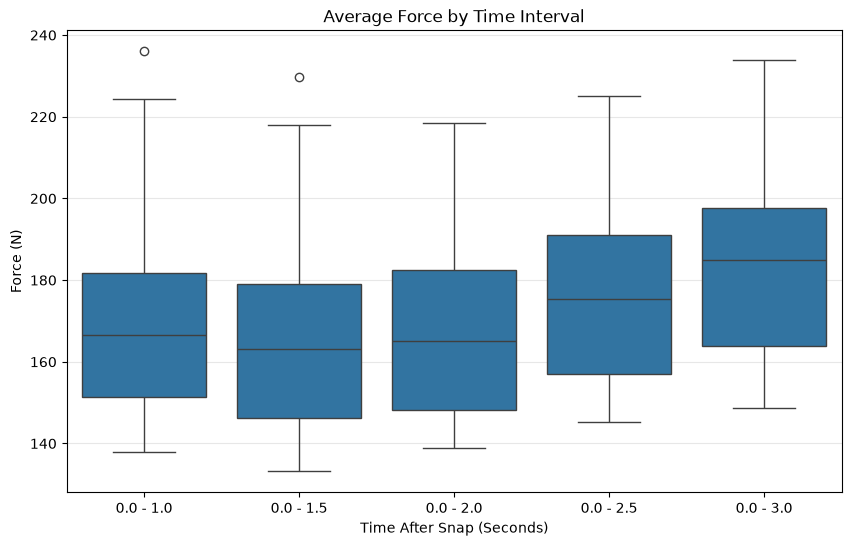

In [55]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=average_acceleration_df,
    x='Time Interval',
    y='Force'
)

plt.title('Average Force by Time Interval')
plt.xlabel('Time After Snap (Seconds)')
plt.ylabel('Force (N)')
plt.grid(axis='y', alpha=0.3)

plt.show()

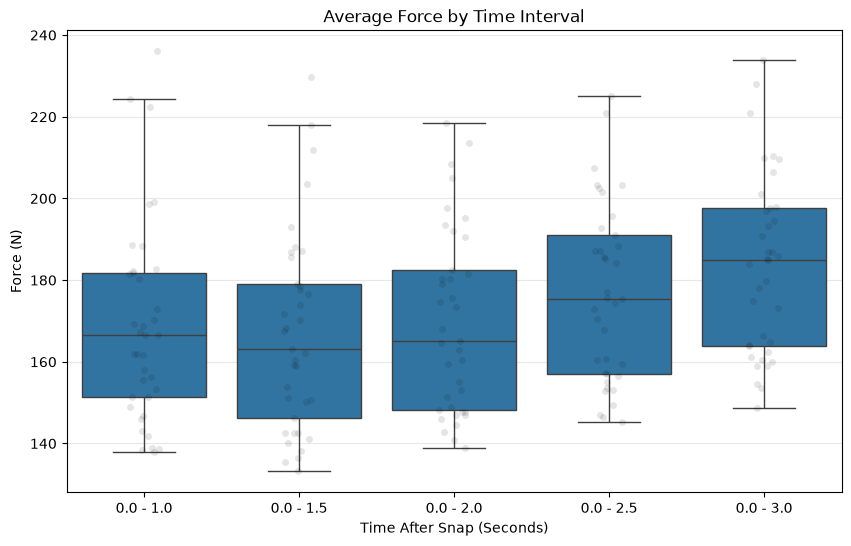

In [54]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=average_acceleration_df,
    x='Time Interval',
    y='Force',
    showfliers=False
)

sns.stripplot(
    data=average_acceleration_df,
    x='Time Interval',
    y='Force',
    color='black',
    alpha=0.1
    ,
    jitter=True
)

plt.title('Average Force by Time Interval')
plt.xlabel('Time After Snap (Seconds)')
plt.ylabel('Force (N)')
plt.grid(axis='y', alpha=0.3)

plt.show()

In [58]:
force_stats = average_acceleration_df.groupby('Time Interval')['Force'].describe()

force_stats

,count,mean,std,min,25%,50%,75%,max
Time Interval,,,,,,,,
0.0 - 1.0,37.0,168.630655,24.642492,137.879029,151.353272,166.483386,181.843141,235.980062
0.0 - 1.5,37.0,166.889366,24.392747,133.138947,146.200640,163.054285,178.988754,229.743297
0.0 - 2.0,37.0,169.761472,22.587359,138.965974,148.182648,164.998055,182.481432,218.438197
0.0 - 2.5,37.0,176.454340,21.817512,145.279346,156.991567,175.261756,190.970784,225.073600
0.0 - 3.0,37.0,183.467736,22.085450,148.622100,163.890686,184.935468,197.597743,233.802509


In [59]:
highest_force = average_acceleration_df.loc[
    average_acceleration_df.groupby('Time Interval')['Force'].idxmax()
]

lowest_force = average_acceleration_df.loc[
    average_acceleration_df.groupby('Time Interval')['Force'].idxmin()
]

print(lowest_force[['nfl_id', 'Time Interval', 'Force']])
print(highest_force[['nfl_id', 'Time Interval', 'Force']])

     nfl_id Time Interval       Force
170   56625     0.0 - 1.0  137.879029
116   56066     0.0 - 1.5  133.138947
137   56183     0.0 - 2.0  138.965974
138   56183     0.0 - 2.5  145.279346
114   56055     0.0 - 3.0  148.622100
    nfl_id Time Interval       Force
90   55983     0.0 - 1.0  235.980062
91   55983     0.0 - 1.5  229.743297
82   55976     0.0 - 2.0  218.438197
83   55976     0.0 - 2.5  225.073600
84   55976     0.0 - 3.0  233.802509


Now we know the stats for the actual players, lets look at the combine too.

The process will be very very similar

# Combine Drills

First we do the same filtering as before, but now we are testing off the combine drills

In [63]:
drills = combine_tracking.merge(
    oline[['nfl_id', 'weight']],
    on='nfl_id',
    how='inner'
)

In [68]:
drills = drills.sort_values(
    ['event_id', 'time']
).copy()

In [ ]:
drills = drills[drills['draft_year'] == 2023] # filter for this data set, so we can compare to our 2023 one

In [76]:
drills

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir,weight
57762,2023,6406869fe3d8e72dcdd1b8cb-2023,55901,PLAYER,2023-03-05T18:12:59.200,FORTY_YARD_DASH,FORTY_YARD_DASH,1,10.766667,-0.833333,0.620000,3.258849,0.001571,85.364537,150.592846
57763,2023,6406869fe3d8e72dcdd1b8cb-2023,55901,PLAYER,2023-03-05T18:12:59.300,FORTY_YARD_DASH,FORTY_YARD_DASH,1,10.866667,-0.833333,1.006667,3.789919,0.010000,85.441210,150.592846
57764,2023,6406869fe3d8e72dcdd1b8cb-2023,55901,PLAYER,2023-03-05T18:12:59.400,FORTY_YARD_DASH,FORTY_YARD_DASH,1,11.000000,-0.800000,1.410000,4.072979,0.017812,84.033504,150.592846
57765,2023,6406869fe3d8e72dcdd1b8cb-2023,55901,PLAYER,2023-03-05T18:12:59.500,FORTY_YARD_DASH,FORTY_YARD_DASH,1,11.133333,-0.800000,1.850000,4.740476,0.017778,84.525444,150.592846
57766,2023,6406869fe3d8e72dcdd1b8cb-2023,55901,PLAYER,2023-03-05T18:12:59.600,FORTY_YARD_DASH,FORTY_YARD_DASH,1,11.366667,-0.766667,2.353333,4.962580,0.054456,85.371092,150.592846
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67573,2023,64068a13e3d8e72dcddcb20a-2023,56572,PLAYER,2023-03-05T21:52:54.900,THREE_CONE_DRILL,THREE_CONE_DRILL,1,97.500000,51.700000,5.610000,4.866210,0.285798,283.747290,140.160209
67574,2023,64068a13e3d8e72dcddcb20a-2023,56572,PLAYER,2023-03-05T21:52:55.000,THREE_CONE_DRILL,THREE_CONE_DRILL,1,96.966667,51.800000,5.723333,3.299604,0.284620,280.642210,140.160209
67575,2023,64068a13e3d8e72dcddcb20a-2023,56572,PLAYER,2023-03-05T21:52:55.100,THREE_CONE_DRILL,THREE_CONE_DRILL,1,96.366667,51.900000,5.890000,2.383858,0.360139,277.543226,140.160209
67576,2023,64068a13e3d8e72dcddcb20a-2023,56572,PLAYER,2023-03-05T21:52:55.200,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.766667,51.966667,5.946667,2.007392,0.360027,275.339835,140.160209


In [79]:
drill_average = (
    drills.groupby(['nfl_id', 'drill_name'])
    .agg(
        average_acceleration=('a', 'mean'),
        weight=('weight', 'first')
    )
    .reset_index()
)

In [83]:
drill_average['Force'] = (
    drill_average['average_acceleration'] *
    drill_average['weight']
)

In [92]:
drill_average

,nfl_id,drill_name,average_acceleration,weight,Force
0,55870,Wave Drill,2.973460,141.974581,422.155739
1,55870,Pull Deep Short Left,2.842468,141.974581,403.558256
2,55870,Pull Fold Right,2.458750,141.974581,349.079931
3,55870,Pull Long Right,3.005433,141.974581,426.695094
4,55870,Mirror Drill,3.640385,141.974581,516.842145
...,...,...,...,...,...
298,56645,Pull Fold Right,2.857972,145.149731,414.833939
299,56645,Pull Long Right,3.043477,145.149731,441.759824
300,56645,Mirror Drill,2.769694,145.149731,402.020364
301,56645,Rush Drop,2.061979,145.149731,299.295727


In [98]:
drill_average['drill_name'] = drill_average['drill_name'].replace({
    'FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE': 'Wave Drill',
    'OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT': 'Pull Deep Short Left',
    'OL_PULL_DRILL_FOLD_BLOCK_RIGHT': 'Pull Fold Right',
    'OL_PULL_DRILL_LONG_PULL_RIGHT': 'Pull Long Right',
    'PASS_PRO_MIRROR_DRILL': 'Mirror Drill',
    'PASS_RUSH_DROP': 'Rush Drop',
    'SCREEN_DRILL': 'Screen Drill',
    'FORTY_YARD_DASH': '40 yd dash',
    'SHORT_SHUTTLE': 'Short Shuttle',
    'THREE_CONE_DRILL': '3-cone drill'
})

In [88]:
drill_average['drill_name'].unique()

<StringArray>
['FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE',
     'OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT',
         'OL_PULL_DRILL_FOLD_BLOCK_RIGHT',
          'OL_PULL_DRILL_LONG_PULL_RIGHT',
                  'PASS_PRO_MIRROR_DRILL',
                         'PASS_RUSH_DROP',
                           'SCREEN_DRILL',
                        'FORTY_YARD_DASH',
                          'SHORT_SHUTTLE',
                       'THREE_CONE_DRILL']
Length: 10, dtype: str

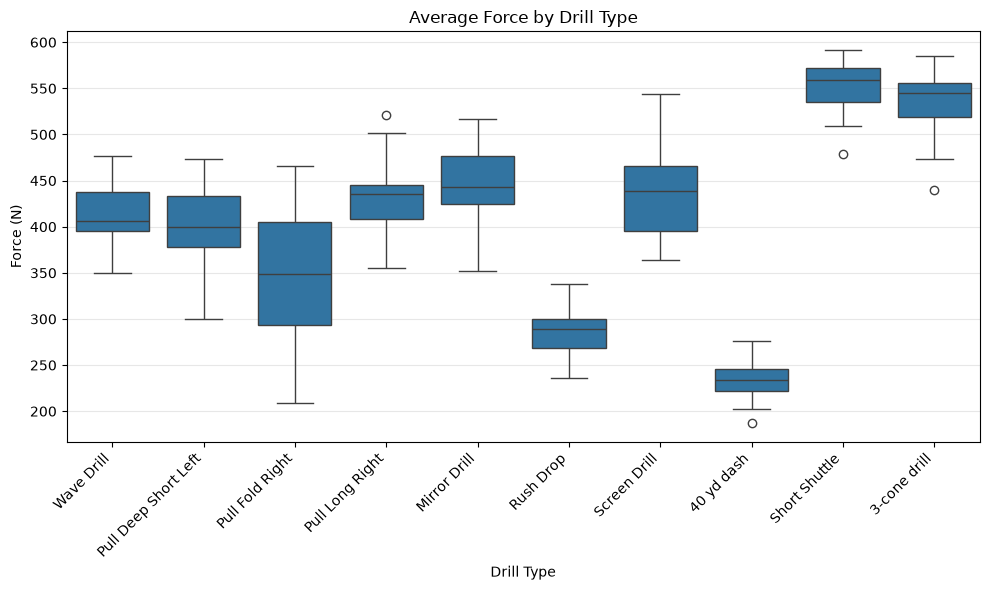

In [99]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=drill_average,
    x='drill_name',
    y='Force'
)

plt.title('Average Force by Drill Type')
plt.xlabel('Drill Type')
plt.ylabel('Force (N)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

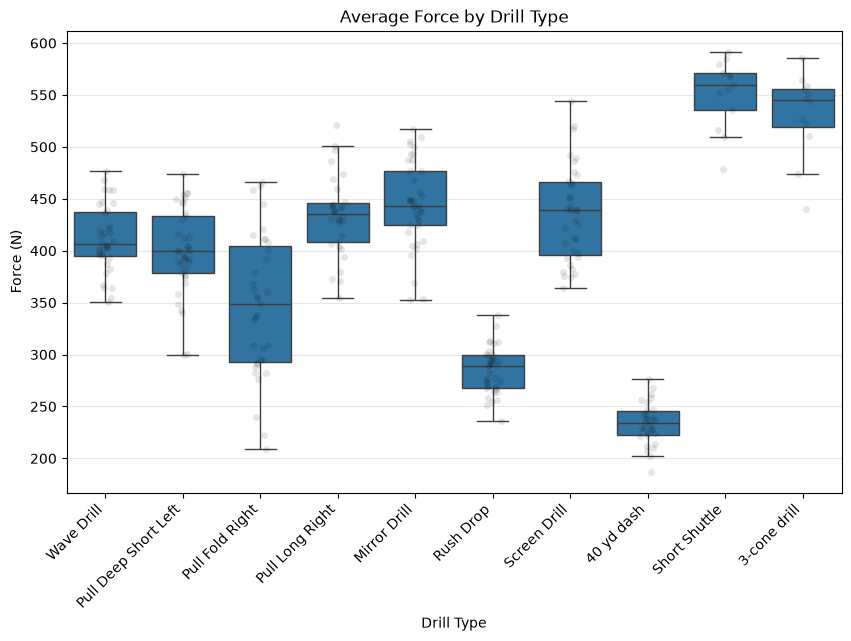

In [100]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=drill_average,
    x='drill_name',
    y='Force',
    showfliers=False
)

sns.stripplot(
    data=drill_average,
    x='drill_name',
    y='Force',
    color='black',
    alpha=0.1
    ,
    jitter=True
)

plt.title('Average Force by Drill Type')
plt.xlabel('Drill Type')
plt.ylabel('Force (N)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)

plt.show()

In [101]:
combine_stats = drill_average.groupby('drill_name')['Force'].describe()

combine_stats

,count,mean,std,min,25%,50%,75%,max
drill_name,,,,,,,,
3-cone drill,12.0,531.458725,40.787177,439.887509,519.479583,545.037515,556.017578,585.484618
40 yd dash,30.0,233.569252,20.091385,187.091452,222.425052,233.880019,245.295130,276.011100
Mirror Drill,37.0,445.539790,42.182156,352.313905,424.437894,443.366849,477.071732,516.842145
Pull Deep Short Left,37.0,399.775744,41.673555,299.663738,378.093953,399.391088,433.542581,473.704578
Pull Fold Right,35.0,346.480755,68.151145,209.446837,293.225684,349.079931,404.713380,466.278664
Pull Long Right,32.0,433.472805,38.270395,354.847427,408.119132,435.079085,445.534837,520.847497
Rush Drop,36.0,285.060000,22.524122,235.610838,268.243846,289.383464,299.460531,338.395567
Screen Drill,35.0,435.178365,46.376175,364.220667,395.807636,439.169450,466.091549,543.915664
Short Shuttle,13.0,551.644997,33.115515,479.085872,535.356725,559.390686,571.542450,591.599685


In [104]:
highest_force_drill = drill_average.loc[
    drill_average.groupby('drill_name')['Force'].idxmax()
]

lowest_force_drill = drill_average.loc[
    drill_average.groupby('drill_name')['Force'].idxmin()
]

print(lowest_force_drill[['nfl_id', 'drill_name', 'Force']])
print(highest_force_drill[['nfl_id', 'drill_name', 'Force']])

     nfl_id            drill_name       Force
72    55922          3-cone drill  439.887509
244   56344            40 yd dash  187.091452
87    55927          Mirror Drill  352.313905
169   56021  Pull Deep Short Left  299.663738
76    55924       Pull Fold Right  209.446837
155   55983       Pull Long Right  354.847427
239   56203             Rush Drop  235.610838
108   55962          Screen Drill  364.220667
23    55875         Short Shuttle  479.085872
280   56625            Wave Drill  350.347814
     nfl_id            drill_name       Force
151   55982          3-cone drill  585.484618
8     55874            40 yd dash  276.011100
4     55870          Mirror Drill  516.842145
75    55924  Pull Deep Short Left  473.704578
138   55976       Pull Fold Right  466.278664
139   55976       Pull Long Right  520.847497
37    55891             Rush Drop  338.395567
38    55891          Screen Drill  543.915664
241   56203         Short Shuttle  591.599685
142   55982            Wave Drill 

# Correlation

reshaping the drill and time intervals because we need them to be similar in order to combine then and find the correlation

In [105]:
drill_wide = drill_average.pivot_table(
    index='nfl_id',
    columns='drill_name',
    values='Force',
    aggfunc='mean'
)

drill_wide.columns = [f'Drill_{col}' for col in drill_wide.columns]

drill_wide.head()

,Drill_3-cone drill,Drill_40 yd dash,Drill_Mirror Drill,Drill_Pull Deep Short Left,Drill_Pull Fold Right,Drill_Pull Long Right,Drill_Rush Drop,Drill_Screen Drill,Drill_Short Shuttle,Drill_Wave Drill
nfl_id,,,,,,,,,,
55870,NaN,NaN,516.842145,403.558256,349.079931,426.695094,295.389204,488.901586,NaN,422.155739
55874,NaN,276.011100,353.106866,392.160935,408.643232,486.102748,312.292429,476.071020,NaN,458.516685
55875,510.401743,228.156266,425.172656,399.391088,239.426915,444.396812,266.502041,440.382753,479.085872,404.022809
55878,NaN,257.952999,456.725139,387.193726,NaN,429.027756,310.839223,NaN,NaN,396.129427
55891,NaN,261.583927,499.525174,300.724661,400.783527,403.660762,338.395567,543.915664,NaN,459.161368


In [106]:
time_wide = average_acceleration_df.pivot_table(
    index='nfl_id',
    columns='Time Interval',
    values='Force',
    aggfunc='mean'
)

time_wide.columns = [f'Time_{col}' for col in time_wide.columns]

time_wide.head()

,Time_0.0 - 1.0,Time_0.0 - 1.5,Time_0.0 - 2.0,Time_0.0 - 2.5,Time_0.0 - 3.0
nfl_id,,,,,
55870,181.843141,185.548272,193.479046,207.342473,220.915340
55874,222.447229,211.868390,213.601410,220.914739,227.940823
55875,182.716667,178.988754,181.517190,188.256968,194.422311
55878,198.650026,193.044296,197.548714,203.387558,210.477955
55891,188.281922,186.764653,192.074203,201.582871,209.893070


In [127]:
combined = drill_wide.merge(
    time_wide,
    on='nfl_id',
    how='inner'
)

combined = combined.reset_index()

combined.head()

,nfl_id,Drill_3-cone drill,Drill_40 yd dash,Drill_Mirror Drill,Drill_Pull Deep Short Left,Drill_Pull Fold Right,Drill_Pull Long Right,Drill_Rush Drop,Drill_Screen Drill,Drill_Short Shuttle,Drill_Wave Drill,Time_0.0 - 1.0,Time_0.0 - 1.5,Time_0.0 - 2.0,Time_0.0 - 2.5,Time_0.0 - 3.0
0,55870,NaN,NaN,516.842145,403.558256,349.079931,426.695094,295.389204,488.901586,NaN,422.155739,181.843141,185.548272,193.479046,207.342473,220.915340
1,55874,NaN,276.011100,353.106866,392.160935,408.643232,486.102748,312.292429,476.071020,NaN,458.516685,222.447229,211.868390,213.601410,220.914739,227.940823
2,55875,510.401743,228.156266,425.172656,399.391088,239.426915,444.396812,266.502041,440.382753,479.085872,404.022809,182.716667,178.988754,181.517190,188.256968,194.422311
3,55878,NaN,257.952999,456.725139,387.193726,NaN,429.027756,310.839223,NaN,NaN,396.129427,198.650026,193.044296,197.548714,203.387558,210.477955
4,55891,NaN,261.583927,499.525174,300.724661,400.783527,403.660762,338.395567,543.915664,NaN,459.161368,188.281922,186.764653,192.074203,201.582871,209.893070


Actually doing the correlation tests

First test is a Pearson model. It measures linear relationships

Second test is a Spearman. It measures if players who rank higher in one measurement also tend to rank higher in another, regardless of linear relationship

In [115]:
drill_cols = [col for col in combined.columns if col.startswith('Drill_')]
time_cols = [col for col in combined.columns if col.startswith('Time_')]

correlations = combined[drill_cols + time_cols].corr(method='pearson')

drill_time_corr = correlations.loc[drill_cols, time_cols]

drill_time_corr.round(3)

,Time_0.0 - 1.0,Time_0.0 - 1.5,Time_0.0 - 2.0,Time_0.0 - 2.5,Time_0.0 - 3.0
Drill_3-cone drill,0.258,0.209,0.186,0.196,0.199
Drill_40 yd dash,0.487,0.481,0.558,0.576,0.551
Drill_Mirror Drill,0.119,0.196,0.181,0.164,0.163
Drill_Pull Deep Short Left,0.140,0.175,0.200,0.174,0.161
Drill_Pull Fold Right,0.254,0.239,0.257,0.219,0.197
Drill_Pull Long Right,0.123,0.125,0.202,0.257,0.275
Drill_Rush Drop,0.263,0.243,0.245,0.241,0.223
Drill_Screen Drill,0.134,0.210,0.325,0.400,0.399
Drill_Short Shuttle,0.105,0.081,-0.057,-0.082,0.011
Drill_Wave Drill,0.394,0.344,0.384,0.423,0.425


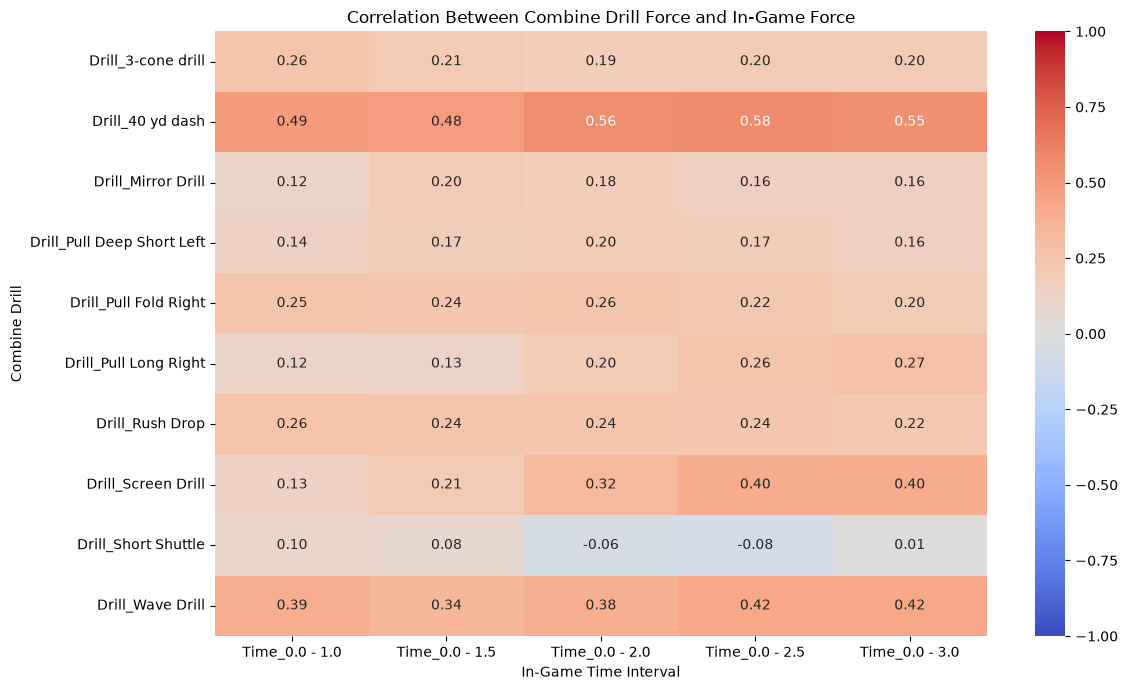

In [112]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    drill_time_corr,
    annot=True,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    fmt='.2f'
)

plt.title('Correlation Between Combine Drill Force and In-Game Force')
plt.xlabel('In-Game Time Interval')
plt.ylabel('Combine Drill')
plt.tight_layout()
plt.show()

In [113]:
spearman_corr = combined[drill_cols + time_cols].corr(method='spearman')

spearman_drill_time = spearman_corr.loc[drill_cols, time_cols]

spearman_drill_time.round(3)

,Time_0.0 - 1.0,Time_0.0 - 1.5,Time_0.0 - 2.0,Time_0.0 - 2.5,Time_0.0 - 3.0
Drill_3-cone drill,0.077,0.049,-0.049,0.098,0.070
Drill_40 yd dash,0.516,0.502,0.604,0.560,0.511
Drill_Mirror Drill,0.249,0.297,0.264,0.219,0.193
Drill_Pull Deep Short Left,0.182,0.188,0.268,0.239,0.216
Drill_Pull Fold Right,0.214,0.210,0.200,0.137,0.127
Drill_Pull Long Right,0.129,0.172,0.183,0.179,0.174
Drill_Rush Drop,0.290,0.265,0.253,0.208,0.187
Drill_Screen Drill,0.128,0.184,0.282,0.370,0.356
Drill_Short Shuttle,0.308,0.286,0.143,0.137,0.126
Drill_Wave Drill,0.345,0.258,0.305,0.332,0.351


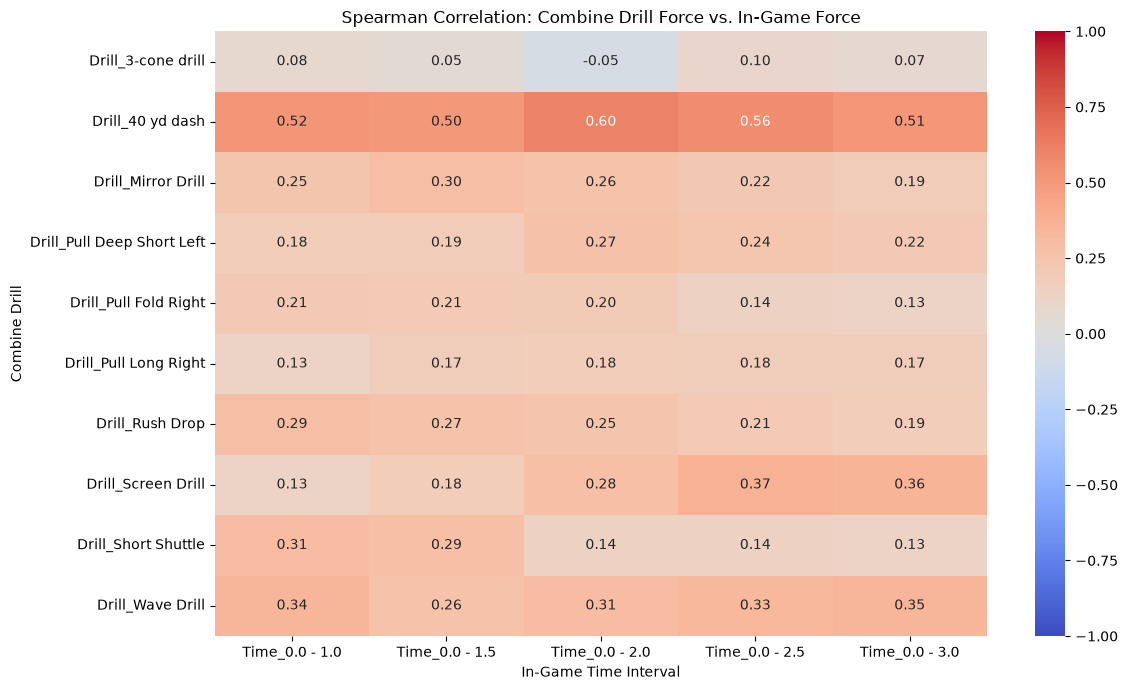

In [114]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    spearman_drill_time,
    annot=True,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    fmt='.2f'
)

plt.title('Spearman Correlation: Combine Drill Force vs. In-Game Force')
plt.xlabel('In-Game Time Interval')
plt.ylabel('Combine Drill')
plt.tight_layout()
plt.show()

# More Checks

Now we want to see some more basic things like p values. Remember, a p-value less than 0.05 is typically worth looking into.

In [118]:
results = []

for drill in drill_cols:
    for interval in time_cols:

        data = combined[[drill, interval]].dropna()

        if len(data) < 3:
            continue

        pearson_r, pearson_p = pearsonr(
            data[drill],
            data[interval]
        )

        spearman_r, spearman_p = spearmanr(
            data[drill],
            data[interval]
        )

        results.append({
            'Drill': drill,
            'Time Interval': interval,
            'Players': len(data),
            'Pearson': pearson_r,
            'Pearson P-Value': pearson_p,
            'Spearman': spearman_r,
            'Spearman P-Value': spearman_p
        })

correlation_results = pd.DataFrame(results)

correlation_results.round(4)

,Drill,Time Interval,Players,Pearson,Pearson P-Value,Spearman,Spearman P-Value
0,Drill_3-cone drill,Time_0.0 - 1.0,12,0.2577,0.4188,0.0769,0.8122
1,Drill_3-cone drill,Time_0.0 - 1.5,12,0.2087,0.5151,0.0490,0.8799
2,Drill_3-cone drill,Time_0.0 - 2.0,12,0.1859,0.5630,-0.0490,0.8799
3,Drill_3-cone drill,Time_0.0 - 2.5,12,0.1956,0.5425,0.0979,0.7621
4,Drill_3-cone drill,Time_0.0 - 3.0,12,0.1986,0.5361,0.0699,0.8290
5,Drill_40 yd dash,Time_0.0 - 1.0,30,0.4865,0.0064,0.5164,0.0035
6,Drill_40 yd dash,Time_0.0 - 1.5,30,0.4814,0.0071,0.5021,0.0047
7,Drill_40 yd dash,Time_0.0 - 2.0,30,0.5576,0.0014,0.6044,0.0004
8,Drill_40 yd dash,Time_0.0 - 2.5,30,0.5758,0.0009,0.5595,0.0013
9,Drill_40 yd dash,Time_0.0 - 3.0,30,0.5511,0.0016,0.5115,0.0039


Testing the 40-yard dash vs the 0 - 2.5 second interval

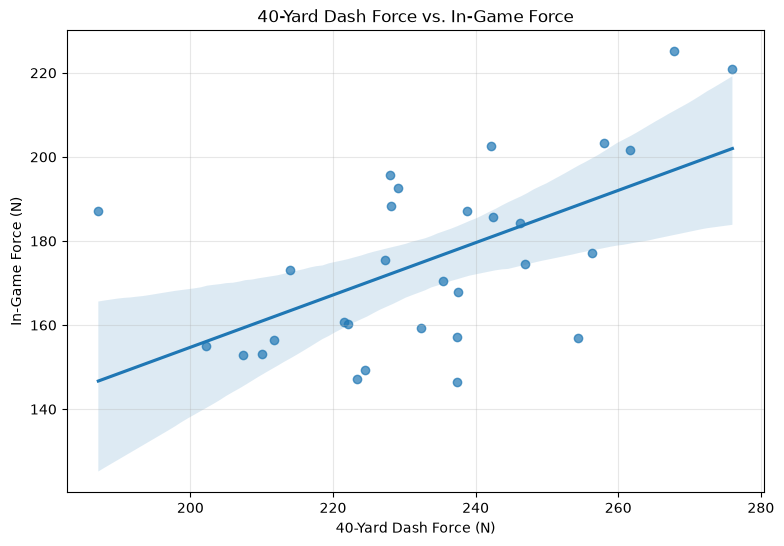

In [119]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=combined,
    x='Drill_40 yd dash',
    y='Time_0.0 - 2.5',
    scatter_kws={'alpha': 0.7}
)

plt.title('40-Yard Dash Force vs. In-Game Force')
plt.xlabel('40-Yard Dash Force (N)')
plt.ylabel('In-Game Force (N)')
plt.grid(alpha=0.3)

plt.show()

My overall thoughts are the 40 time and the wave drill seem to be the most promising. They both measure movement, and the ability to show movement is most easily shown with this force metric. I certainly would like to do more investigation, but I will say that overall I am very satisfied with my results.

# Let us see if some of our results actually are correct

In [149]:
first_round_23 = average_acceleration_df[
    average_acceleration_df['nfl_id'].isin([55874, 55870, 55875, 55878, 55891])
]

first_round_23 = first_round_23.merge(
    players[['nfl_id', 'display_name']],
    on='nfl_id',
    how='left'
)

first_round_23.insert(
    1,
    'display_name',
    first_round_23.pop('display_name')
)

first_round_23 = first_round_23.sort_values(
    ['Time Interval', 'Force'])

first_round_23

,nfl_id,display_name,Time Interval,Average Acceleration,weight,Force
0,55870,Paris Johnson,0.0 - 1.0,1.280815,141.974581,181.843141
10,55875,Peter Skoronski,0.0 - 1.0,1.286967,141.974581,182.716667
20,55891,Anton Harrison,0.0 - 1.0,1.317746,142.881766,188.281922
15,55878,Broderick Jones,0.0 - 1.0,1.408192,141.067395,198.650026
5,55874,Darnell Wright,0.0 - 1.0,1.472708,151.046439,222.447229
11,55875,Peter Skoronski,0.0 - 1.5,1.260710,141.974581,178.988754
1,55870,Paris Johnson,0.0 - 1.5,1.306912,141.974581,185.548272
21,55891,Anton Harrison,0.0 - 1.5,1.307127,142.881766,186.764653
16,55878,Broderick Jones,0.0 - 1.5,1.368454,141.067395,193.044296
6,55874,Darnell Wright,0.0 - 1.5,1.402671,151.046439,211.868390


In [147]:
first_23_success = career_success[
    career_success['nfl_id'].isin([55874, 55870, 55875, 55878, 55891])
]

first_23_success = first_23_success.merge(
    players[['nfl_id', 'display_name']],
    on='nfl_id',
    how='left'
)

first_23_success.insert(
    1,
    'display_name',
    first_23_success.pop('display_name')
)

first_23_success

,nfl_id,display_name,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started,ap_all_pro_1st_team,ap_all_pro_2nd_team,pro_bowl_original_ballot
0,55870,Paris Johnson,2802,0,169,47,43,0,0,0
1,55874,Darnell Wright,3222,0,167,51,49,0,1,0
2,55875,Peter Skoronski,3011,0,170,51,48,0,0,0
3,55878,Broderick Jones,2468,0,149,45,38,0,0,0
4,55891,Anton Harrison,3026,0,183,51,48,0,0,0


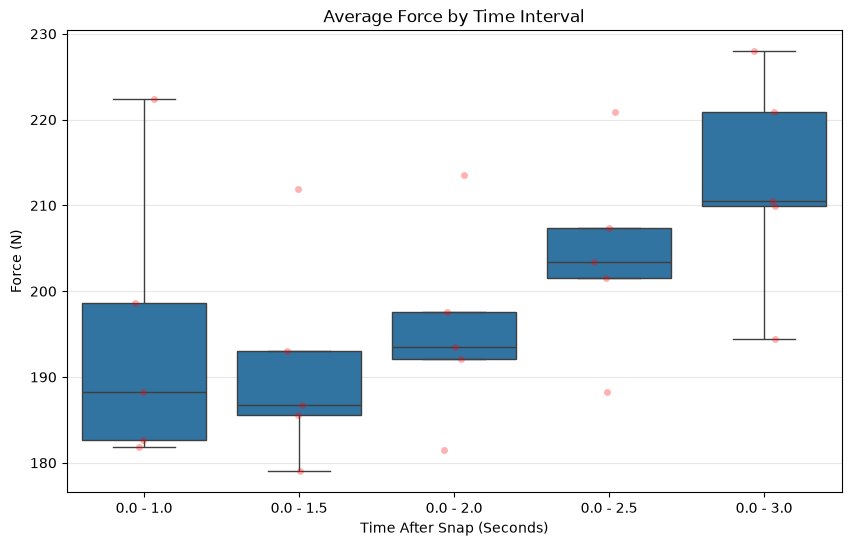

In [145]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=first_round_23,
    x='Time Interval',
    y='Force',
    showfliers=False
)

sns.stripplot(
    data=first_round_23,
    x='Time Interval',
    y='Force',
    color='red',
    alpha=0.3
    ,
    jitter=True
)

plt.title('Average Force by Time Interval')
plt.xlabel('Time After Snap (Seconds)')
plt.ylabel('Force (N)')
plt.grid(axis='y', alpha=0.3)

plt.show()